In [1]:
import nescafe23 as n23
import numpy as np

In [3]:
dss = n23.open_receptions()

100%|██████████| 23/23 [00:16<00:00,  1.39it/s]


In [8]:
# Load FCTD
fctd = n23.compute_filtered_fctd_grid(
    z_smooth=200,
    r_smooth=5e3,
)
fctd = fctd.assign_coords(
    {"range": fctd.range.values + 35e3}
)  # change front location

fctd = fctd.isel({'range': slice(1, -1)})
#fctd = fctd.interp({'range':np.linspace(0, 200e3, 500)})

/home/john.ragland/Code/NESMA/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)


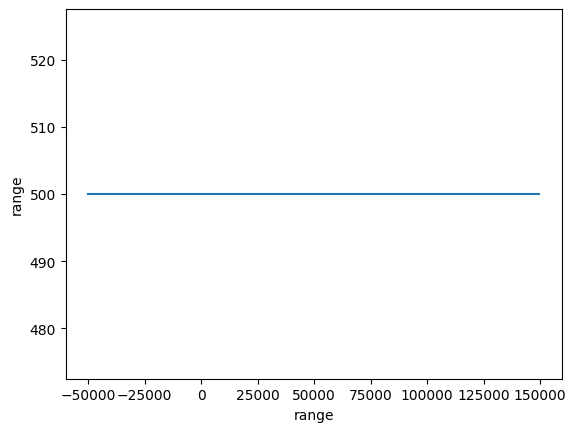

In [9]:
fctd.range[1:-1].diff('range').plot()

In [11]:
fctd_mat = {
    't': fctd.t.values,
    'SP': fctd.SP.values,
    'c': fctd.c.values,
    'N': fctd.N.values,
    'SA': fctd.SA.values,
    'depth': fctd.depth.values,
    'range': fctd.range.values
}

from scipy import io
io.savemat("n23_fctd_jr2.mat", fctd_mat)

In [13]:
import matplotlib.pyplot as plt

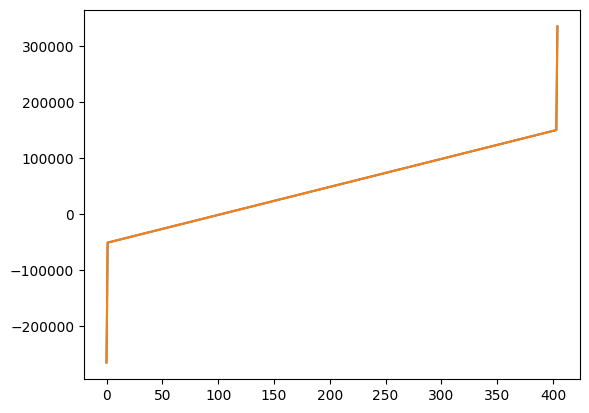

In [15]:
plt.plot(fctd_mat['range'])
plt.plot(fctd.range)

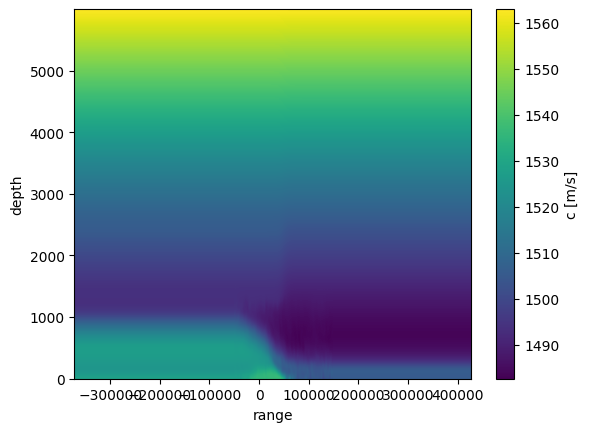

In [11]:
fctd['c'].plot()